# Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the clean data

In [2]:
orders = pd.read_csv("/Users/anhtuyet15999/Projects/ecommerce_delivery_time/data/processed/clean_orders.csv")

In [3]:
order_items = pd.read_csv("/Users/anhtuyet15999/Projects/ecommerce_delivery_time/data/processed/clean_order_items.csv")

In [4]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,item_total,freight_total,total_order_value,payment_total,payment_record_count,payment_type_count,customer_lat,customer_lng,delivery_time_days,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,29.99,8.72,38.71,38.71,3.0,2.0,-23.576170,-46.587276,8.436574,-8.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,118.70,22.76,141.46,141.46,1.0,1.0,-12.126651,-45.008162,13.782037,-6.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,159.90,19.22,179.12,179.12,1.0,1.0,-16.744472,-48.514624,9.394213,-18.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,...,45.00,27.20,72.20,72.20,1.0,1.0,-5.774611,-35.273916,13.208750,-13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,...,19.90,8.72,28.62,28.62,1.0,1.0,-23.675316,-46.515116,2.873877,-10.0


In [5]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_length,product_description_length,...,item_total,freight_total,total_order_value,payment_total,payment_record_count,payment_type_count,customer_lat,customer_lng,delivery_time_days,delivery_delay_days
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,...,58.90,13.29,72.19,72.19,1.0,1.0,-21.762829,-41.310605,7.614421,-9.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,...,239.90,19.93,259.83,259.83,1.0,1.0,-20.205737,-50.926924,16.216181,-3.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,...,199.00,17.87,216.87,216.87,1.0,1.0,-19.870383,-44.594355,7.948437,-14.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,...,12.99,12.79,25.78,25.78,1.0,1.0,-23.104346,-46.595589,6.147269,-6.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,...,199.90,18.14,218.04,218.04,1.0,1.0,-23.245512,-46.825182,25.114352,-16.0


# Exploratory Data Analysis

## Select Orders with Valid Delivery Times

In [6]:
delivery = orders[
    (orders["order_status"] == "delivered")
    & (orders["delivery_time_days"].notna())
    & (orders["delivery_time_days"] >= 0)
].copy()

print("All orders:", len(orders))
print("Orders used for delivery time analysis:", len(delivery))

All orders: 99441
Orders used for delivery time analysis: 96470


## Delivery Time Distribution

### Summary Statistics

In [7]:
delivery["delivery_time_days"].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_time_days, dtype: float64

### Distribution Plot

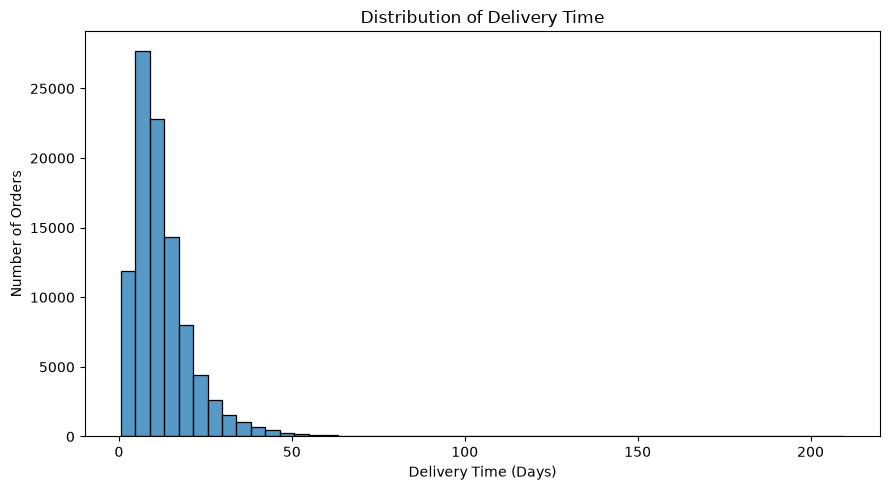

In [8]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=delivery,
    x="delivery_time_days",
    bins=50
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

### Summary
The delivery time distribution is right-skewed. Among 96,470 delivered orders with valid delivery times, the mean delivery time is 12.56 days, while the median is 10.22 days. The middle 50% of orders were delivered within 6.77 to 15.72 days. A small number of orders have much longer delivery times, with a maximum of 209.63 days. These extreme values require further investigation before deciding whether to exclude them.

## Delivery Time by Customer State

### Summary Statistics by State

In [9]:
state_summary = delivery.groupby("customer_state").agg(
    order_count=("order_id", "size"),
    mean_delivery_days=("delivery_time_days", "mean"),
    median_delivery_days=("delivery_time_days", "median")
)

state_summary = state_summary.sort_values(
    "median_delivery_days"
)

state_summary.round(2)

,order_count,mean_delivery_days,median_delivery_days
customer_state,,,
SP,40494,8.76,7.21
MG,11354,12.01,10.31
PR,4923,11.99,10.43
DF,2080,12.97,11.36
RJ,12350,15.31,12.04
SC,3546,14.95,13.01
RS,5344,15.30,13.18
ES,1995,15.79,13.64
MS,701,15.62,13.94


### Median Delivery Time by State

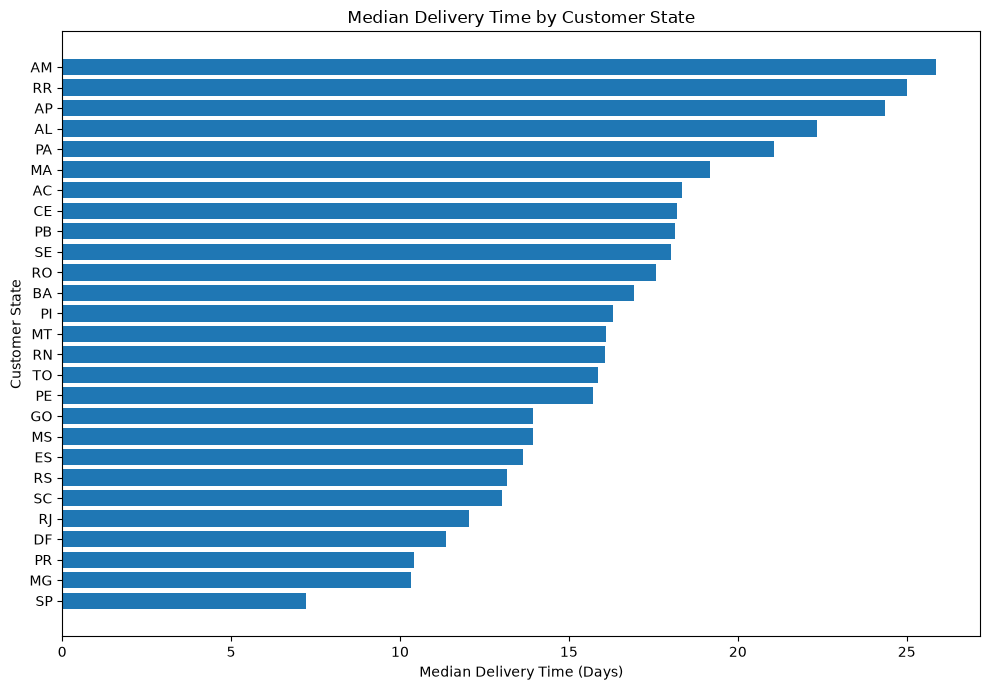

In [10]:
plt.figure(figsize=(10, 7))

plt.barh(
    state_summary.index,
    state_summary["median_delivery_days"]
)

plt.title("Median Delivery Time by Customer State")
plt.xlabel("Median Delivery Time (Days)")
plt.ylabel("Customer State")

plt.tight_layout()
plt.show()

### Summary
Median delivery times vary across customer states. SP has the shortest median delivery time at 7.21 days, while AM has the longest at 25.88 days. However, sample sizes differ considerably: SP has 40,494 orders, compared with 145 in AM and 41 in RR. These results suggest an association between customer location and delivery time, but do not establish causation. Differences in seller location, shipping distance, and order characteristics may also contribute.

## Order Value and Delivery Time

### Select Orders with Known Order Values

In [11]:
value_delivery = delivery[
    delivery["total_order_value"].notna()
].copy()

### Scatter Plot

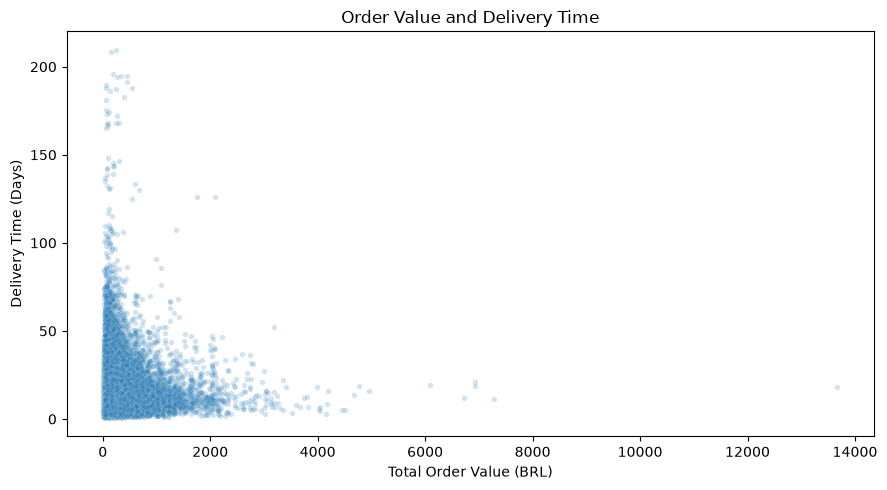

In [12]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=value_delivery,
    x="total_order_value",
    y="delivery_time_days",
    alpha=0.2,
    s=15
)

plt.title("Order Value and Delivery Time")
plt.xlabel("Total Order Value (BRL)")
plt.ylabel("Delivery Time (Days)")

plt.tight_layout()
plt.show()

### Spearman Correlation

In [13]:
correlation = value_delivery["total_order_value"].corr(
    value_delivery["delivery_time_days"],
    method="spearman"
)

print("Correlation:", round(correlation, 3))

Correlation: 0.143


### Summary
The Spearman correlation between total order value and delivery time is 0.143, indicating a weak positive association. Higher-value orders tend to have slightly longer delivery times, but the relationship is weak. Total order value includes freight charges, so the association may also reflect shipping costs and other order characteristics.

## Delivery Time by Item Count

### Summary Statistics

In [14]:
item_delivery = delivery[
    delivery["item_count"].notna()
].copy()

# Group orders into 1, 2, 3, and 4+ items
item_delivery["item_group"] = pd.cut(
    item_delivery["item_count"],
    bins=[0, 1, 2, 3, float("inf")],
    labels=["1 item", "2 items", "3 items", "4+ items"]
)

item_count_summary = item_delivery.groupby(
    "item_group",
    observed=True
).agg(
    order_count=("order_id", "size"),
    median_delivery_days=("delivery_time_days", "median")
)

item_count_summary.round(2)

,order_count,median_delivery_days
item_group,,
1 item,86835,10.26
2 items,7392,9.87
3 items,1306,9.86
4+ items,937,10.17


### Median Delivery Time by Item Count

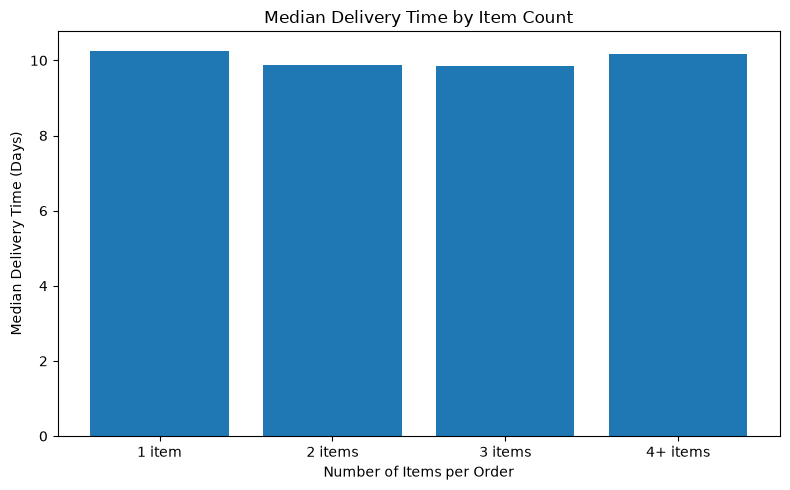

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    item_count_summary.index.astype(str),
    item_count_summary["median_delivery_days"]
)

plt.title("Median Delivery Time by Item Count")
plt.xlabel("Number of Items per Order")
plt.ylabel("Median Delivery Time (Days)")

plt.tight_layout()
plt.show()

### Summary
Median delivery times are similar across item-count groups, ranging from 9.86 to 10.26 days. There is no clear increasing trend in median delivery time as item count rises. However, group sizes are highly unequal, with 86,835 single-item orders and only 937 orders containing four or more items. This comparison alone does not establish whether item count is a useful predictor.

## Delivery Time by Seller Count

### Create Seller Groups

In [16]:
seller_delivery = delivery[
    delivery["seller_count"].notna()
    & (delivery["seller_count"] >= 1)
].copy()

seller_delivery["seller_group"] = "Multiple sellers"

seller_delivery.loc[
    seller_delivery["seller_count"] == 1,
    "seller_group"
] = "Single seller"

### Summary Statistics

In [17]:
seller_summary = seller_delivery.groupby("seller_group").agg(
    order_count=("order_id", "size"),
    mean_delivery_days=("delivery_time_days", "mean"),
    median_delivery_days=("delivery_time_days", "median")
)

seller_summary.round(2)

,order_count,mean_delivery_days,median_delivery_days
seller_group,,,
Multiple sellers,1275,9.14,7.93
Single seller,95195,12.60,10.25


### Median Delivery Time by Seller Group

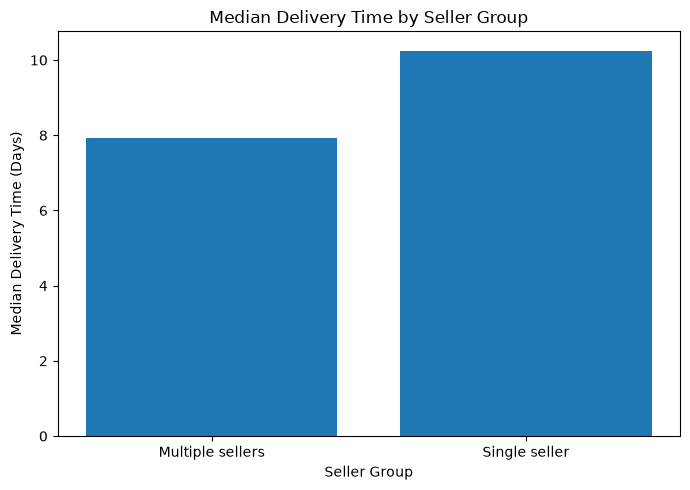

In [18]:
plt.figure(figsize=(7, 5))

plt.bar(
    seller_summary.index,
    seller_summary["median_delivery_days"]
)

plt.title("Median Delivery Time by Seller Group")
plt.xlabel("Seller Group")
plt.ylabel("Median Delivery Time (Days)")

plt.tight_layout()
plt.show()

### Summary
Orders with multiple sellers have a shorter median delivery time (7.93 days) than orders with a single seller (10.25 days), a difference of approximately 2.32 days. However, the groups are highly unequal in size: 1,275 orders involve multiple sellers, compared with 95,195 single-seller orders. This comparison does not establish causation; differences in customer location, seller location, and product characteristics may contribute to the observed pattern.

# Planned EDA Extensions:
- Distance and Delivery Time: Explore how seller–customer distance is associated with delivery time. For orders involving multiple sellers, compare mean and maximum distances.
- Monthly Delivery Time Trends: Examine changes in median delivery time by purchase month, alongside monthly order counts.
- Product Weight and Volume: Investigate whether heavier or bulkier orders tend to take longer to arrive. Aggregate item characteristics to the order level and account for missing measurements.
- On-Time and Late Deliveries: Calculate the proportion of orders delivered on or before the estimated delivery date versus after it. Compare late-delivery rates across customer states and purchase months
- Product Categories: Compare delivery times across product categories, reporting order counts for each category. Count each order once per category and note that orders containing multiple categories can appear in more than one group.